# 06 - Analyse par commune et distance à Paris

**Objectif** : comprendre comment le prix au m² varie d'une commune à l'autre en Seine-et-Marne, et tester l'hypothèse « le prix baisse quand on s'éloigne de Paris ».

**Entrée** : `dvf_77_2025_analyse.parquet` (13 712 ventes, sortie du notebook 05).
**Sortie** : `dvf_77_2025_enrichi.parquet` (mêmes ventes + colonne `distance_paris_km`).

**Plan**
1. Répartition des ventes par commune et choix d'un seuil de fiabilité
2. Classement des communes (plus chères / moins chères)
3. Distance à Paris et lien avec le prix
4. Effet de composition : maisons / appartements
5. Cas d'étude : Noisiel
6. Vue d'ensemble : nuage de points par commune

## 0. Chargement des données

In [27]:
import pandas as pd
import numpy as np
import seaborn as sns


df = pd.read_parquet("../data/processed/dvf_77_2025_analyse.parquet")
print(df.shape)

(13712, 14)


## 1. Répartition des ventes par commune

Le jeu contient 484 communes, mais la commune médiane n'a que 8 ventes : une médiane de prix calculée sur si peu de ventes n'est pas fiable.

In [28]:
repartition_commune = df['nom_commune'].value_counts()

print(repartition_commune)

repartition_commune.describe()



nom_commune
Chelles                    567
Meaux                      535
Melun                      408
Pontault Combault          357
Bussy-Saint-Georges        310
                          ... 
Saint-Germain-sous-Doue      1
Melz-sur-Seine               1
Leudon-en-Brie               1
Trocy-en-Multien             1
Montdauphin                  1
Name: count, Length: 484, dtype: int64


count    484.000000
mean      28.330579
std       61.539079
min        1.000000
25%        4.000000
50%        8.000000
75%       21.000000
max      567.000000
Name: count, dtype: float64

### Choix d'un seuil de fiabilité

On compare trois seuils minimaux de ventes par commune. **Décision** : on garde toutes les communes dans le jeu de données (on ne supprime rien) et on n'applique un seuil qu'à l'affichage des classements et des graphiques (30 ventes, qui conserve 93 communes et 76,8 % des ventes).

In [29]:
total_ventes = len(df)

seuils = [10, 30, 50]
lignes = []

for seuil in seuils:
    communes_gardees = repartition_commune[repartition_commune >= seuil]
    lignes.append({
        "seuil_ventes_min": seuil,
        "nb_communes": len(communes_gardees),
        "ventes_couvertes": communes_gardees.sum(),
        "part_des_ventes_%": round(communes_gardees.sum() / total_ventes * 100, 1),
    })

tableau_seuils = pd.DataFrame(lignes)
print(tableau_seuils)

print("Ventes à Noisiel :", repartition_commune["Noisiel"])

   seuil_ventes_min  nb_communes  ventes_couvertes  part_des_ventes_%
0                10          215             12554               91.6
1                30           93             10528               76.8
2                50           66              9530               69.5
Ventes à Noisiel : 94


## 2. Classement des communes par prix médian

Seules les communes d'au moins 30 ventes sont classées.

In [30]:
stats_commune = df.groupby("nom_commune")["prix_m2"].agg(
    mediane="median",
    nb_ventes="count",
)

seuil = 30
classement = stats_commune[stats_commune["nb_ventes"] >= seuil].sort_values("mediane", ascending=False)

print("--- 10 communes les plus chères ---")
print(classement.head(10))

print("--- 10 communes les moins chères ---")
print(classement.tail(10))

print("--- Noisiel ---")
print(stats_commune.loc["Noisiel"])

--- 10 communes les plus chères ---
                           mediane  nb_ventes
nom_commune                                  
Serris                 4787.402670        108
Magny-le-Hongre        4725.274725         95
Fontainebleau          4696.153846        234
Chessy                 4602.347488        102
Montevrain             4508.771930        213
Ferrieres-en-Brie      4438.750000         50
Bussy-Saint-Georges    4307.692308        310
Bois le Roi            4230.769231         57
Bailly-Romainvilliers  4123.198529         84
Coupvray               3967.062500         30
--- 10 communes les moins chères ---
                              mediane  nb_ventes
nom_commune                                     
Saint-Mammes              2352.777778         48
Varennes-sur-Seine        2276.470588         32
Nangis                    2256.551724         57
Le Mee sur Seine          2201.566224        116
Saint-Pierre-les-Nemours  2189.189189         51
Provins                   2089.7

**Lecture** : les communes les plus chères sont autour de Marne-la-Vallée (Serris, Magny-le-Hongre, Chessy, Montévrain, Bussy-Saint-Georges) ainsi que Fontainebleau et Bois-le-Roi. Les moins chères sont en périphérie de département (Nemours, Provins, Montereau, Souppes). Noisiel (94 ventes, 3 301 €/m²) est une commune intermédiaire.

## 3. Distance à Paris

On calcule pour chaque vente la distance à vol d'oiseau (formule de haversine) jusqu'à Notre-Dame de Paris. Les 6 ventes sans coordonnées GPS gardent une distance manquante : on ne les impute pas.

In [31]:
# 1. Y a-t-il des coordonnées manquantes ?
print(df[["latitude", "longitude"]].isna().sum())

# 2. Distance à Paris (point de référence : Notre-Dame)
lat_paris, lon_paris = 48.8534, 2.3488

def distance_km(lat1, lon1, lat2, lon2):
    rayon_terre = 6371
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = phi2 - phi1
    dlambda = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda / 2) ** 2
    return 2 * rayon_terre * np.arcsin(np.sqrt(a))

df["distance_paris_km"] = distance_km(df["latitude"], df["longitude"], lat_paris, lon_paris)
print(df["distance_paris_km"].describe())

latitude     6
longitude    6
dtype: int64
count    13706.000000
mean        39.318413
std         16.549338
min         16.284347
25%         26.355298
50%         35.870433
75%         49.124370
max         91.801661
Name: distance_paris_km, dtype: float64


### Prix médian par tranche de distance

In [32]:
# 1. Les 6 ventes sans coordonnées GPS
colonnes = ["nom_commune", "type_local", "surface_reelle_bati", "valeur_fonciere", "prix_m2"]
print(df.loc[df["latitude"].isna(), colonnes])

# 2. prix_m2 selon la distance à Paris
tranches_distance = pd.cut(df["distance_paris_km"], bins=[0, 20, 30, 40, 50, 60, 100])

stats_distance = df.groupby(tranches_distance)["prix_m2"].agg(
    mediane="median",
    nb_ventes="count",
)
print(stats_distance)

               nom_commune type_local  surface_reelle_bati  valeur_fonciere  \
5331         Vaux-le-Penil     Maison                158.0         170000.0   
5527          Saint-Mammes     Maison                 59.0         275000.0   
6119    Varennes-sur-Seine     Maison                 93.0         180000.0   
12123  Saint-Cyr-sur-Morin     Maison                 90.0         209000.0   
12943             Dampmart     Maison                130.0         380000.0   
13679    Mareuil-les-Meaux     Maison                100.0         280000.0   

           prix_m2  
5331   1075.949367  
5527   4661.016949  
6119   1935.483871  
12123  2322.222222  
12943  2923.076923  
13679  2800.000000  
                       mediane  nb_ventes
distance_paris_km                        
(0, 20]            3518.082789        998
(20, 30]           3553.731343       3965
(30, 40]           3230.769231       2751
(40, 50]           2827.256718       2646
(50, 60]           2701.351351       1452
(60, 

**Lecture** : le prix médian baisse globalement avec la distance (3 518 €/m² à moins de 20 km, 1 963 €/m² au-delà de 60 km), avec une légère hausse entre les deux premières tranches.

## 4. Effet de composition : maisons et appartements

Les maisons sont globalement moins chères au m² que les appartements. Est-ce dû au type de bien ou à leur éloignement de Paris ? On regarde la part de chaque type par tranche, puis le prix à type et distance fixés (principe : isoler avant de comparer).

In [33]:
# 1. Part de chaque type de bien dans chaque tranche de distance
print(pd.crosstab(tranches_distance, df["type_local"], normalize="index").round(2))

# 2. Médiane et effectifs par tranche ET par type de bien
stats_type_distance = df.groupby([tranches_distance, "type_local"])["prix_m2"].agg(
    mediane="median",
    nb_ventes="count",
)
print(stats_type_distance)

type_local         Appartement  Maison
distance_paris_km                     
(0, 20]                   0.56    0.44
(20, 30]                  0.53    0.47
(30, 40]                  0.42    0.58
(40, 50]                  0.47    0.53
(50, 60]                  0.38    0.62
(60, 100]                 0.20    0.80
                                   mediane  nb_ventes
distance_paris_km type_local                         
(0, 20]           Appartement  3362.068966        560
                  Maison       3656.596906        438
(20, 30]          Appartement  3636.363636       2092
                  Maison       3464.285714       1873
(30, 40]          Appartement  3607.843137       1157
                  Maison       3053.410853       1594
(40, 50]          Appartement  2805.555556       1247
                  Maison       2833.333333       1399
(50, 60]          Appartement  3045.248869        550
                  Maison       2571.147357        902
(60, 100]         Appartement  2012.1951

**Lecture** : près de Paris, appartements et maisons sont en nombre comparable ; plus on s'éloigne, plus les maisons dominent (80 % au-delà de 60 km). Une partie de l'écart global maison/appartement vient donc de la localisation. À distance égale, l'écart entre types reste présent mais instable selon la tranche.

## 5. Cas d'étude : Noisiel

Noisiel est à la limite de deux tranches (≈ 20 km). On compare ses prix à ceux de sa tranche, par type de bien.

In [34]:
noisiel = df[df["nom_commune"] == "Noisiel"]

print("Distance médiane à Paris :", noisiel["distance_paris_km"].median())
print(noisiel.groupby("type_local")["prix_m2"].agg(mediane="median", nb_ventes="count"))

Distance médiane à Paris : 19.987954627135366
                 mediane  nb_ventes
type_local                         
Appartement  3110.331867         60
Maison       3421.458838         34


**Lecture** : les maisons de Noisiel sont proches de la médiane de leur tranche, alors que les appartements sont nettement en dessous (7 à 15 %). Hypothèse (non vérifiée) : un parc ancien et mixte, avec des ventes en bloc de logements.

## 6. Vue d'ensemble : prix médian par commune selon la distance

Chaque point est une commune d'au moins 30 ventes ; sa taille représente le nombre de ventes.

Text(0, 0.5, 'prix_m2 médian (€/m²)')

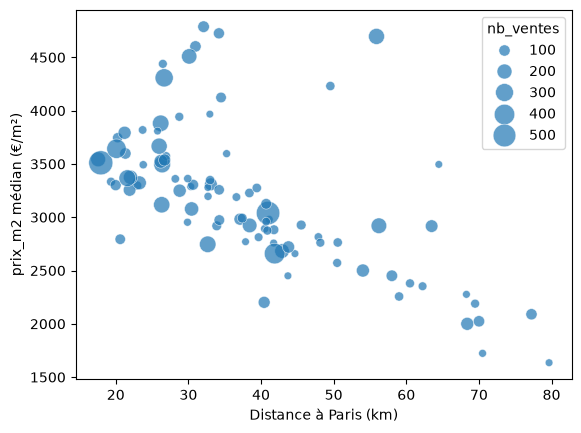

In [35]:

stats_commune_dist = df.groupby("nom_commune").agg(
    mediane_prix_m2=("prix_m2", "median"),
    distance_km=("distance_paris_km", "median"),
    nb_ventes=("prix_m2", "count"),
).dropna()

communes_fiables = stats_commune_dist[stats_commune_dist["nb_ventes"] >= 30]

ax = sns.scatterplot(
    data=communes_fiables,
    x="distance_km",
    y="mediane_prix_m2",
    size="nb_ventes",
    sizes=(30, 300),
    alpha=0.7,
)
ax.set_xlabel("Distance à Paris (km)")
ax.set_ylabel("prix_m2 médian (€/m²)")

**Lecture** : la tendance est décroissante (corrélation ≈ −0,63 sur 93 communes) mais dispersée. Plusieurs communes s'écartent nettement du gradient : Fontainebleau et Bois-le-Roi (loin mais chères) et les communes de Marne-la-Vallée (distance moyenne mais très chères). Hypothèses : forêt et cadre résidentiel d'un côté, constructions neuves et desserte de l'autre. Ces facteurs ne sont pas dans nos données, donc non vérifiables ici.

## 7. Sauvegarde du jeu de données enrichi

On ajoute `distance_paris_km` au jeu du notebook 05 et on sauvegarde dans un **nouveau fichier** (la chaîne raw → propre → filtre → analyse → enrichi n'écrase aucune étape).

In [36]:
df.to_parquet("../data/processed/dvf_77_2025_enrichi.parquet", index=False)
print(df.shape)

(13712, 15)


## Conclusion

- **Communes** : 484 communes, mais la commune médiane n'a que 8 ventes. On garde toutes les communes dans le jeu de données et on ne filtre (≥ 30 ventes) qu'à l'affichage. Les médianes sur de petits effectifs sont à interpréter avec prudence.
- **Distance à Paris** : le prix au m² baisse globalement avec la distance (≈ 3 500 €/m² à moins de 30 km contre ≈ 1 960 €/m² au-delà de 60 km). La corrélation commune par commune est d'environ −0,63 : la tendance est nette mais loin d'expliquer tout.
- **Composition** : la part de maisons augmente avec la distance, ce qui explique une partie de l'écart global maison/appartement. Le reste varie selon la tranche et est instable.
- **Limites de la distance seule** : Fontainebleau et Bois-le-Roi, ainsi que les communes de Marne-la-Vallée, sont bien plus chères que ce que leur distance prédit. Les causes possibles (cadre, neuf, transports) ne sont pas dans nos données.
- **Pour la modélisation** : `distance_paris_km` est une variable utile (6 valeurs manquantes à traiter), mais la commune (ou une variable qui la résume) devra probablement aussi être utilisée pour capter les effets locaux.

**Fichier produit** : `dvf_77_2025_enrichi.parquet` (13 712 lignes, 15 colonnes).
**Prochaine étape** : évolution mensuelle des prix en 2025 (notebook 07).